In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np 
import cftime

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [5]:
#here we focus on the asymmetric baseline simulation
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot 

#/falwa_output/

#years_range = range(13, 613)
#files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in years_range]

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS


In [6]:
#ds = xr.open_mfdataset(files_falwa,combine='nested',concat_dim='time',parallel=True, chunks={'time': 1000})
ds = xr.open_dataset('dw_lwa_1.5x1.5_2-51.nc')
ds = flip_and_append(ds)

In [7]:
work_dir='/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot/'
fn_out_unfilt = work_dir + "falwa_LWAA_tracked_unfilt_flipped_2.5x2.5_daily_2-51_perc.nc"
fn_out = work_dir + "falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_perc.nc"
fn_dic_unfilt = work_dir + "dictionaries/falwa_LWAA_tracked_unfilt_flipped_2.5x2.5_daily_2-51_DIC_perc.npy"
fn_dic = work_dir + "dictionaries/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51_DIC_perc.npy" 

In [8]:
import importlib
import blocktoolbox as BT

importlib.reload(BT)

<module 'blocktoolbox' from '/emmy-noether/home/mf671/github/blocktrack/lib/blocktoolbox.py'>

In [9]:
ds = BT.LWAA_perc(ds,perc=90,lwa_name='dw_lwa')
ds,dic_unfilt = BT.ContourTracking2D(ds,var_name = "LWAA",geop_name='dw_lwa',overlap=0.5,grid=1.5)

__Starting a LWA anomaly process__
input: dw_lwa , percentile = 90
(36000, 61, 240)
computing the 90th percentile of the distribution
mean: 13.234407158051, percentile:10.842514883314841


100%|███████████████████████████████████████████████████████████████| 35910/35910 [00:11<00:00, 3243.69it/s]


__Starting a Tracking process__
input: LWAA
connected component analysis


100%|████████████████████████████████████████████████████████████████| 36000/36000 [00:41<00:00, 859.09it/s]


rearranging indexes


100%|█████████████████████████████████████████████████████████████████| 36000/36000 [11:51<00:00, 50.63it/s]


calculating characteristics
persistence, track, date:


100%|█████████████████████████████████████████████████████████████████| 36000/36000 [21:52<00:00, 27.42it/s]


area, WBI and intensity


100%|███████████████████████████████████████████████████████████████| 36000/36000 [1:06:10<00:00,  9.07it/s]


number of labels: 234968.0


In [10]:
ds.to_netcdf(fn_out_unfilt)
np.save(fn_dic_unfilt,dic_unfilt)

In [11]:
ds_filt,dic_filt = BT.FilterEvents(ds,dic_unfilt,var_name = "LWAA",pers_min = 5,min_avg_area = 3e6)
print("ContourTracking2D function correclty executed")
#saving data
np.save(fn_dic,dic_filt)
ds_filt.to_netcdf(fn_out)
print("Data created")

__Starting a Filtering process__
input: LWAA_tracked
applying filters


100%|████████████████████████████████████████████████████████████| 234968/234968 [00:06<00:00, 35387.56it/s]


rearranging indexes


100%|███████████████████████████████████████████████████████████████| 36000/36000 [00:04<00:00, 8444.99it/s]


number of labels: 2136
2136
ContourTracking2D function correclty executed
Data created


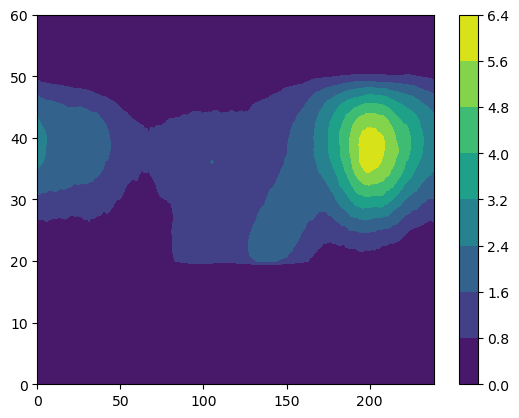

In [12]:
plt.contourf(ds_filt['LWAA_freq'])
plt.colorbar()